
---
date: "2026-11-13"
date-modified: last-modified
format:
  html:
    toc: true
---


# Point Processes and the Poisson Process

**Prerequisites:** [Poisson distribution](poisson-distribution.ipynb) · [Exponential distribution](exponential-distribution.ipynb) · [Gamma distribution](gamma-function-and-distribution.ipynb#def-gamma-distribution) · [Order statistics](order-statistics.ipynb#thm-uniform-order-statistics) · [Independence of random variables](independence-of-rvs.ipynb)

A **point process** models events that happen at random instants: trades in a limit order book, earthquakes, neuron spikes. The Poisson process is the point process *without memory*: the rate of new events never depends on what happened before. Every model in the [Hawkes series](index-hawkes-processes.ipynb) is built by changing exactly this one feature, so we develop the Poisson process carefully, together with the two tools used later to simulate Hawkes processes: superposition and thinning.

## 1\. Counting Processes and Point Processes

::: {#def-counting-process}
## Counting process, point process
A **counting process** is a stochastic process $(N_t)_{t \ge 0}$ with $N_0 = 0$, values in $\{0, 1, 2, \dots\}$, nondecreasing and right-continuous paths that increase only by jumps of size $+1$, and $N_t < \infty$ for every $t$.

Its jump times $0 < T_1 < T_2 < \cdots$ (the **event times** or **arrival times**) form a **point process**, and conversely
$$
N_t = \sum_{k \ge 1} \mathbf{1}\{T_k \le t\}, \qquad N(a, b] := N_b - N_a = \#\{k : a < T_k \le b\}.
$$
We write $T_0 := 0$ and call $E_k := T_k - T_{k-1}$ the **inter-arrival times**. Jumps of size $+1$ mean that no two events happen at the same time; such a process is called **simple**.
:::

The two descriptions carry the same information: the path $t \mapsto N_t$ is a staircase, and the event times are the positions of its steps. We use $N_t$ and $N(t)$ interchangeably.

::: {.callout-warning}
## Right-continuous counts, left-continuous rates
$N_t$ counts events in $(0, t]$, so it is right-continuous: $N_{T_k} = k$. The *rates* introduced later (intensities) will be left-continuous: the rate at the instant $T_k$ is the rate just *before* the event. Mixing up the two conventions is the most common bug when evaluating likelihoods.
:::

## 2\. The Homogeneous Poisson Process

::: {#def-poisson-process}
## Homogeneous Poisson process
A counting process $N$ is a **(homogeneous) Poisson process with rate $\lambda > 0$** if

1. it has **independent increments**: for $0 \le t_0 < t_1 < \cdots < t_m$, the counts $N(t_0, t_1], \dots, N(t_{m-1}, t_m]$ are independent;
2. every increment is Poisson: $N(s, s + t] \sim \operatorname{Pois}(\lambda t)$ for all $s, t \ge 0$.
:::

There are two other common descriptions: one through the waiting times, one through what happens in a short interval.

::: {#thm-poisson-from-exponential-gaps}
## Construction from exponential gaps
Let $E_1, E_2, \dots$ be i.i.d. $\operatorname{Expo}(\lambda)$, $S_k = E_1 + \cdots + E_k$ and $N_t = \#\{k : S_k \le t\}$. Then:

1. For every $T > 0$ and $n \ge 0$, $\;P(N_T = n) = e^{-\lambda T}(\lambda T)^n / n!$.
2. Conditionally on $N_T = n$, the vector $(S_1, \dots, S_n)$ has the density $n!/T^n$ on $\{0 < s_1 < \cdots < s_n < T\}$: the event times are distributed as the [order statistics](order-statistics.ipynb#thm-uniform-order-statistics) of $n$ i.i.d. $\operatorname{Unif}(0, T)$ variables.
3. $N$ is a Poisson process with rate $\lambda$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-poisson-from-exponential-gaps
**Joint density of the arrival times.** The vector $(E_1, \dots, E_{n+1})$ has density $\prod_{k=1}^{n+1}\lambda e^{-\lambda e_k} = \lambda^{n+1}e^{-\lambda(e_1 + \cdots + e_{n+1})}$ on $(0,\infty)^{n+1}$. The map $(e_1, \dots, e_{n+1}) \mapsto (s_1, \dots, s_{n+1})$, $s_k = e_1 + \cdots + e_k$, is linear, triangular with ones on the diagonal (Jacobian $1$), and maps $(0,\infty)^{n+1}$ onto $\{0 < s_1 < \cdots < s_{n+1}\}$. Hence $(S_1, \dots, S_{n+1})$ has density
$$
g(s_1, \dots, s_{n+1}) = \lambda^{n+1} e^{-\lambda s_{n+1}}, \qquad 0 < s_1 < \cdots < s_{n+1}.
$$

**Parts 1 and 2.** The event $\{N_T = n,\ S_1 \in ds_1, \dots, S_n \in ds_n\}$ with $s_n < T$ is $\{S_1 \in ds_1, \dots, S_n \in ds_n,\ S_{n+1} > T\}$. Integrating out $s_{n+1}$,
$$
\int_T^\infty \lambda^{n+1} e^{-\lambda s_{n+1}}\, ds_{n+1} = \lambda^n e^{-\lambda T}, \qquad 0 < s_1 < \cdots < s_n < T .
$$
This "joint density" of $(S_1,\dots,S_n)$ on the event $\{N_T = n\}$ is constant. The simplex $\{0 < s_1 < \cdots < s_n < T\}$ has volume $T^n/n!$ (the cube $(0,T)^n$ splits into $n!$ congruent pieces, one for each ordering of the coordinates, up to a null set). Therefore $P(N_T = n) = \lambda^n e^{-\lambda T}\, T^n / n!$, which is part 1, and the conditional density is $\lambda^n e^{-\lambda T} / P(N_T = n) = n!/T^n$, which is part 2.

**Part 3.** Fix $0 = t_0 < t_1 < \cdots < t_m = T$ and write $I_j = (t_{j-1}, t_j]$. By part 2, given $N_T = n$ the *unordered* event times are i.i.d. uniform on $(0,T]$, so each lands in $I_j$ with probability $|I_j|/T$, independently. The counts $(N(I_1), \dots, N(I_m))$ are therefore multinomial given $N_T = n$, and for $k_1 + \cdots + k_m = n$,
$$
\begin{aligned}
P\big(N(I_1) = k_1, \dots, N(I_m) = k_m\big)
&= \frac{e^{-\lambda T}(\lambda T)^n}{n!} \cdot \frac{n!}{k_1! \cdots k_m!}\prod_{j=1}^m \Big(\frac{|I_j|}{T}\Big)^{k_j} \\
&= \prod_{j=1}^m e^{-\lambda |I_j|}\frac{(\lambda |I_j|)^{k_j}}{k_j!},
\end{aligned}
$$
using $T = \sum_j |I_j|$ and $T^n = \prod_j T^{k_j}$. The joint pmf factorizes into Poisson pmfs, so the increments over $I_1, \dots, I_m$ are independent with $N(I_j) \sim \operatorname{Pois}(\lambda|I_j|)$. Any finite family of disjoint intervals is contained in such a partition of some $[0, T]$, so both conditions of @def-poisson-process hold. $\blacksquare$
:::

Since the law of a counting process is determined by the joint laws of its counts on finitely many intervals, @thm-poisson-from-exponential-gaps also shows the converse: *every* Poisson process has i.i.d. $\operatorname{Expo}(\lambda)$ inter-arrival times. In particular $E[E_k] = 1/\lambda$ and $N_t/t \to \lambda$ almost surely by the [strong law of large numbers](law-of-large-numbers-and-central-limit-theorem.ipynb#thm-strong-lln) applied to $S_k/k \to 1/\lambda$.

::: {#thm-poisson-infinitesimal}
## Infinitesimal description
Let $N$ be a counting process with independent increments such that, for every $t \ge 0$, as $h \downarrow 0$,
$$
P\big(N(t, t+h] = 1\big) = \lambda h + o(h), \qquad P\big(N(t, t+h] \ge 2\big) = o(h),
$$
with $o(h)$ uniform in $t$. Then $N$ is a Poisson process with rate $\lambda$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-poisson-infinitesimal
Fix $s \ge 0$ and put $p_k(t) = P(N(s, s+t] = k)$. By independent increments,
$$
p_0(t + h) = P\big(N(s, s+t] = 0\big)\,P\big(N(s+t, s+t+h] = 0\big) = p_0(t)\big(1 - \lambda h + o(h)\big),
$$
so $(p_0(t+h) - p_0(t))/h \to -\lambda p_0(t)$; the same computation from $t - h$ gives the left derivative. With $p_0(0) = 1$ this gives $p_0(t) = e^{-\lambda t}$. For $k \ge 1$, splitting according to the number of events in $(s+t, s+t+h]$,
$$
p_k(t+h) = p_k(t)(1 - \lambda h) + p_{k-1}(t)\,\lambda h + o(h),
$$
because the cases with two or more events in the short interval contribute $o(h)$. Hence $p_k' = -\lambda p_k + \lambda p_{k-1}$ with $p_k(0) = 0$. Multiplying by $e^{\lambda t}$, $(e^{\lambda t}p_k)' = \lambda e^{\lambda t}p_{k-1}$. If $p_{k-1}(t) = e^{-\lambda t}(\lambda t)^{k-1}/(k-1)!$, integration gives $e^{\lambda t}p_k(t) = (\lambda t)^k/k!$. By induction $N(s, s+t] \sim \operatorname{Pois}(\lambda t)$ for every $s$, and independent increments are assumed. $\blacksquare$
:::

::: {.callout-note}
## Intuition: memorylessness
In every short interval $(t, t+h]$ an event occurs with probability $\approx \lambda h$, *whatever happened before $t$*. A Poisson process cannot "remember" a burst of activity. Real event streams (trades, quote updates, aftershocks) visibly cluster, so they violate exactly this property. The [Hawkes process](hawkes-process.ipynb) replaces the constant $\lambda$ by a rate that jumps up after every event.
:::

## 3\. Inhomogeneous Poisson Processes

::: {#def-inhomogeneous-poisson}
## Inhomogeneous Poisson process
Let $\lambda : [0, \infty) \to [0, \infty)$ be locally integrable and $\Lambda(t) = \int_0^t \lambda(s)\, ds$. A counting process is an **inhomogeneous Poisson process with rate function $\lambda$** if it has independent increments and $N(a, b] \sim \operatorname{Pois}\big(\Lambda(b) - \Lambda(a)\big)$ for all $a < b$.
:::

Intraday trading activity is a standard example: the rate of trades is high after the open, low at lunch and high again before the close (the "U-shape").

::: {#thm-poisson-time-change}
## Time change
Assume $\lambda > 0$, so that $\Lambda$ is continuous and strictly increasing, and $\Lambda(t) \to \infty$.

1. If $N$ is an inhomogeneous Poisson process with rate $\lambda$, then $\tilde N_s := N\big(\Lambda^{-1}(s)\big)$ is a Poisson process with rate $1$.
2. Conversely, if $S_1 < S_2 < \cdots$ are the event times of a rate-$1$ Poisson process, then $T_k := \Lambda^{-1}(S_k)$ are the event times of an inhomogeneous Poisson process with rate $\lambda$.
3. Given $N_T = n$, the unordered event times in $(0, T]$ are i.i.d. with density $\lambda(t)/\Lambda(T)$ on $(0, T]$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-poisson-time-change
1. Since $\Lambda^{-1}$ is increasing, disjoint intervals $(a, b]$ in the new clock correspond to disjoint intervals $(\Lambda^{-1}(a), \Lambda^{-1}(b)]$ in the old one, so $\tilde N$ has independent increments, and $\tilde N(a, b] = N(\Lambda^{-1}(a), \Lambda^{-1}(b)] \sim \operatorname{Pois}(b - a)$.
2. Let $M$ be the rate-$1$ process. The number of $T_k$ in $(a, b]$ equals the number of $S_k$ in $(\Lambda(a), \Lambda(b)]$, which is $\operatorname{Pois}(\Lambda(b) - \Lambda(a))$, and independence of increments transfers in the same way.
3. By part 1 and @thm-poisson-from-exponential-gaps, given $\tilde N_{\Lambda(T)} = n$ the times $S_k = \Lambda(T_k)$ are i.i.d. uniform on $(0, \Lambda(T)]$ (unordered). If $U$ is uniform on $(0, \Lambda(T)]$, then $P(\Lambda^{-1}(U) \le t) = P(U \le \Lambda(t)) = \Lambda(t)/\Lambda(T)$, whose derivative is $\lambda(t)/\Lambda(T)$. $\blacksquare$
:::

Part 1 is the simplest instance of a general fact, the [time-rescaling theorem](conditional-intensity-and-compensator.ipynb#thm-time-rescaling): any point process becomes a unit-rate Poisson process when time is measured by its compensator. That theorem is the basis of goodness-of-fit testing for Hawkes models.

## 4\. Superposition and Thinning

::: {#thm-superposition}
## Superposition
If $N^{(1)}, \dots, N^{(m)}$ are independent inhomogeneous Poisson processes with rates $\lambda_1, \dots, \lambda_m$, then $N = N^{(1)} + \cdots + N^{(m)}$ is an inhomogeneous Poisson process with rate $\lambda_1 + \cdots + \lambda_m$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-superposition
For disjoint intervals $I_1, \dots, I_r$, the family $\{N^{(i)}(I_j)\}_{i, j}$ is independent (independence across $i$ by assumption, across $j$ by independent increments of each $N^{(i)}$). Hence the sums $N(I_j) = \sum_i N^{(i)}(I_j)$ are independent in $j$. A sum of independent Poisson variables is Poisson with the sum of the means (multiply the [MGFs](moment-generating-functions.ipynb) $e^{m_i(e^s - 1)}$), so $N(I_j) \sim \operatorname{Pois}\big(\sum_i \int_{I_j}\lambda_i\big)$. $\blacksquare$
:::

With probability one no two independent processes jump at the same time (each event time of one has a continuous distribution, so it avoids the countably many event times of the other), so the superposition is again simple.

::: {#thm-thinning}
## Thinning
Let $N$ be a homogeneous Poisson process with rate $M$ on $(0, T]$ and let $\lambda : (0, T] \to [0, M]$ be measurable. Keep each event $t$ of $N$ independently with probability $\lambda(t)/M$ and discard it otherwise. Then the kept events form an inhomogeneous Poisson process with rate $\lambda$, the discarded events form one with rate $M - \lambda$, and the two are independent.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-thinning
Fix a partition $I_1, \dots, I_m$ of $(0, T]$ into intervals. Given $N_T = n$, the $n$ unordered events are i.i.d. uniform (@thm-poisson-from-exponential-gaps), and each one is kept or discarded independently. So each event falls, independently of the others, into one of the $2m$ cells "kept in $I_j$" and "discarded in $I_j$" with probabilities
$$
q_j = \frac{1}{T}\int_{I_j}\frac{\lambda(t)}{M}\,dt = \frac{a_j}{MT}, \qquad r_j = \frac{1}{T}\int_{I_j}\Big(1 - \frac{\lambda(t)}{M}\Big)dt = \frac{b_j}{MT},
$$
where $a_j = \int_{I_j}\lambda$ and $b_j = \int_{I_j}(M - \lambda)$; note $\sum_j (a_j + b_j) = MT$. The cell counts $(K_j, D_j)$ are multinomial given $N_T = n$, and exactly as in part 3 of the proof of @thm-poisson-from-exponential-gaps,
$$
P(K_j = k_j, D_j = d_j \ \forall j) = \frac{e^{-MT}(MT)^n}{n!}\cdot\frac{n!}{\prod_j k_j!\, d_j!}\prod_j \Big(\frac{a_j}{MT}\Big)^{k_j}\Big(\frac{b_j}{MT}\Big)^{d_j} = \prod_j e^{-a_j}\frac{a_j^{k_j}}{k_j!}\, e^{-b_j}\frac{b_j^{d_j}}{d_j!}.
$$
All $2m$ counts are independent Poisson with means $a_j$ and $b_j$, which is the claim. $\blacksquare$
:::

::: {.callout-note}
## Intuition: thinning as rejection sampling in time
Throw points uniformly at rate $M$ under the flat ceiling $y = M$, give each a uniform height $U \in (0, M)$, and keep the points with $U \le \lambda(t)$. The kept points are uniform under the graph of $\lambda$, which is exactly an inhomogeneous Poisson process with rate $\lambda$. [Ogata's algorithm](hawkes-simulation.ipynb#thm-ogata-thinning) for Hawkes processes applies the same idea with a ceiling that is updated after every event.
:::

::: {.callout-note}
## Algorithm: simulating Poisson processes on $(0, T]$
**Homogeneous, rate $\lambda$.** Draw $n \sim \operatorname{Pois}(\lambda T)$, then $n$ i.i.d. $\operatorname{Unif}(0, T)$ times and sort them (by @thm-poisson-from-exponential-gaps). Equivalently, add i.i.d. $\operatorname{Expo}(\lambda)$ gaps until $T$ is exceeded.

**Inhomogeneous, rate $\lambda \le M$.** Simulate a homogeneous process with rate $M$; keep a point $t$ if $U \le \lambda(t)$, with $U \sim \operatorname{Unif}(0, M)$ independent (by @thm-thinning).
:::

## 5\. The Variance-to-Mean Ratio

For a Poisson process, $\operatorname{Var} N(t, t+\tau] = E\, N(t, t+\tau] = \lambda\tau$ for every window length $\tau$, so the **Fano factor** (variance-to-mean ratio of counts)
$$
F(\tau) = \frac{\operatorname{Var} N(t, t+\tau]}{E\, N(t, t+\tau]}
$$
equals $1$ at every scale. Clustered data have $F(\tau) > 1$, increasingly so at long windows. For a stationary Hawkes process $F(\tau) \to 1/(1 - \eta)^2$ as $\tau \to \infty$, where $\eta$ is the branching ratio ([Hawkes process](hawkes-process.ipynb#thm-hawkes-second-order)). Measuring $F(\tau)$ is the quickest test of whether a Poisson model is adequate.

## 6\. Simulation on Mock Data

We simulate a rate-$2$ Poisson process and check the three facts proved above: Poisson counts, exponential gaps, and uniform event times given the count.

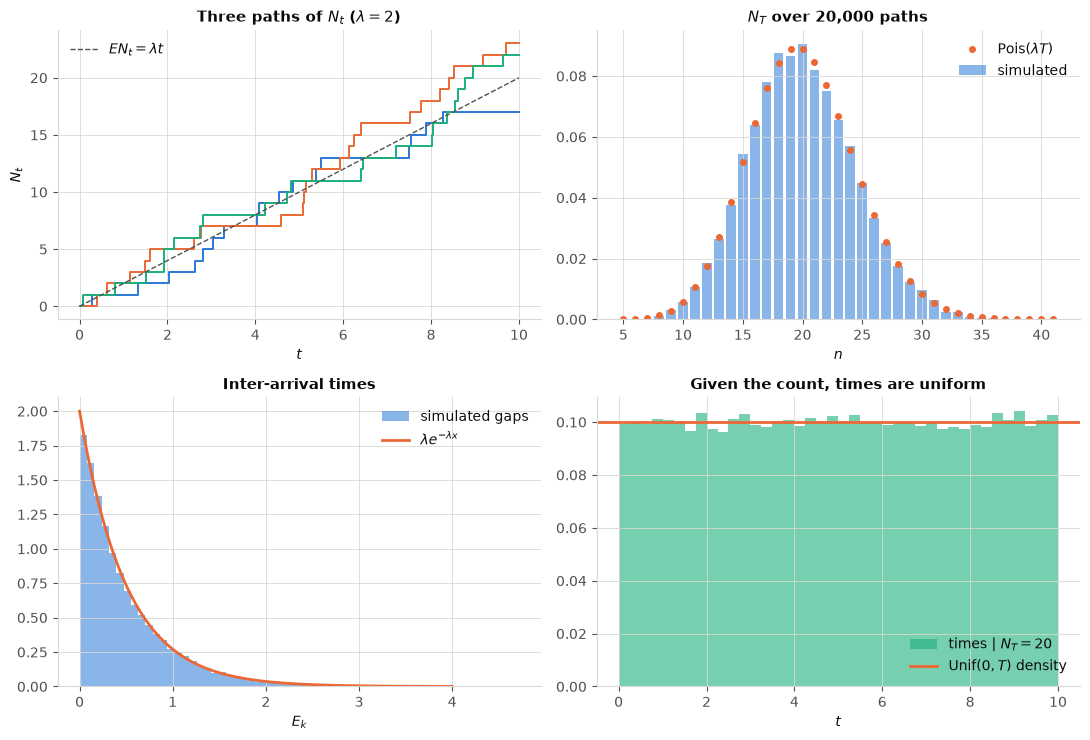

mean N_T = 19.981 (theory 20.0),  var N_T = 19.960 (theory 20.0)
KS test of gaps vs Expo(2): p = 0.269


In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from scipy import stats

rng = np.random.default_rng(1)
lam, T = 2.0, 10.0

def poisson_process(lam, T, rng):
    """Event times of a homogeneous Poisson process on (0, T]: Poisson count + sorted uniforms."""
    n = rng.poisson(lam * T)
    return np.sort(rng.uniform(0, T, n))

fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))

# (a) sample paths
for k, c in enumerate([BLUE, ORANGE, AQUA]):
    t = poisson_process(lam, T, rng)
    ax[0, 0].step(np.r_[0, t, T], np.r_[0, np.arange(1, len(t) + 1), len(t)], where="post", color=c, lw=1.4)
ax[0, 0].plot([0, T], [0, lam * T], color=MUTED, ls="--", lw=1, label=r"$E N_t = \lambda t$")
ax[0, 0].set(title="Three paths of $N_t$ ($\\lambda = 2$)", xlabel="$t$", ylabel="$N_t$"); ax[0, 0].legend()

# (b) counts N_T over many replications vs Poisson pmf
counts = np.array([len(poisson_process(lam, T, rng)) for _ in range(20000)])
k = np.arange(counts.min(), counts.max() + 1)
ax[0, 1].bar(k, np.bincount(counts)[k] / len(counts), color=BLUE, alpha=0.55, label="simulated")
ax[0, 1].plot(k, stats.poisson.pmf(k, lam * T), "o", color=ORANGE, ms=4, label=r"Pois$(\lambda T)$")
ax[0, 1].set(title="$N_T$ over 20,000 paths", xlabel="$n$"); ax[0, 1].legend()

# (c) inter-arrival times vs Expo(lambda)
long_path = poisson_process(lam, 10000.0, rng)   # built from a Poisson count + sorted uniforms
E = np.diff(np.r_[0, long_path])                 # its gaps should be i.i.d. Expo(lambda)
x = np.linspace(0, 4, 200)
ax[1, 0].hist(E, bins=60, density=True, color=BLUE, alpha=0.55, label="simulated gaps")
ax[1, 0].plot(x, lam * np.exp(-lam * x), color=ORANGE, lw=2, label=r"$\lambda e^{-\lambda x}$")
ax[1, 0].set(title="Inter-arrival times", xlabel="$E_k$"); ax[1, 0].legend()

# (d) conditional uniformity: event times of paths with exactly n = 20 events
times = np.concatenate([t for t in (poisson_process(lam, T, rng) for _ in range(40000)) if len(t) == 20])
ax[1, 1].hist(times, bins=40, density=True, color=AQUA, alpha=0.6, label="times | $N_T = 20$")
ax[1, 1].axhline(1 / T, color=ORANGE, lw=2, label="Unif$(0, T)$ density")
ax[1, 1].set(title="Given the count, times are uniform", xlabel="$t$"); ax[1, 1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"mean N_T = {counts.mean():.3f} (theory {lam*T}),  var N_T = {counts.var():.3f} (theory {lam*T})")
print(f"KS test of gaps vs Expo(2): p = {stats.kstest(E, 'expon', args=(0, 1/lam)).pvalue:.3f}")


Next, an inhomogeneous process with a U-shaped intraday rate, simulated by thinning. Time runs over one trading day rescaled to $(0, 1]$, and the rate is $\lambda(t) = 200 + 1600\,(t - 1/2)^2$ events per day, so it rises from $200$ at midday to $600$ at the open and the close; the ceiling is $M = 600$.

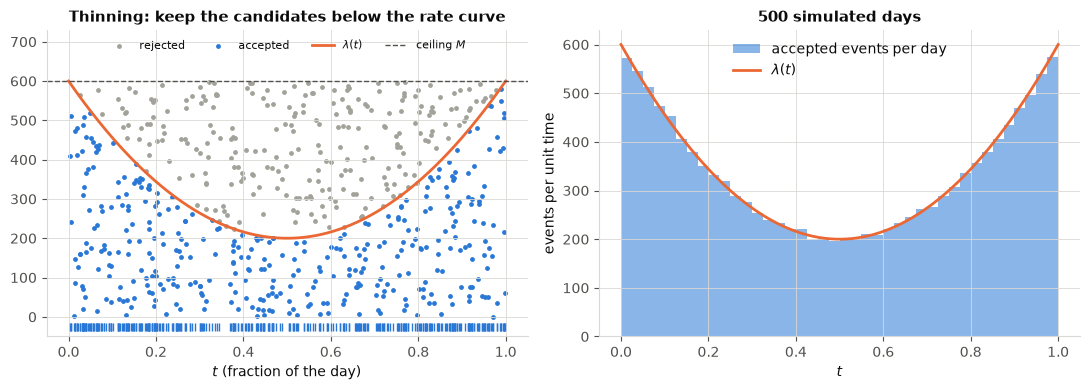

mean events per day = 332.9 (theory 333.3)


In [2]:

rate = lambda t: 200 + 1600 * (t - 0.5) ** 2
M, T = 600.0, 1.0
rng = np.random.default_rng(7)

def thinning(rate, M, T, rng):
    cand = poisson_process(M, T, rng)            # candidates under the ceiling
    u = rng.uniform(0, M, len(cand))             # uniform heights
    keep = u <= rate(cand)
    return cand, u, keep

cand, u, keep = thinning(rate, M, T, rng)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tt = np.linspace(0, 1, 400)
ax[0].scatter(cand[~keep], u[~keep], s=6, color="#a3a29a", label="rejected")
ax[0].scatter(cand[keep], u[keep], s=6, color=BLUE, label="accepted")
ax[0].plot(tt, rate(tt), color=ORANGE, lw=2, label=r"$\lambda(t)$")
ax[0].axhline(M, color=MUTED, ls="--", lw=1, label="ceiling $M$")
ax[0].plot(cand[keep], np.full(keep.sum(), -25), "|", color=BLUE, ms=6)
ax[0].set(title="Thinning: keep the candidates below the rate curve", xlabel="$t$ (fraction of the day)", ylim=(-50, 730))
ax[0].legend(loc="upper center", ncol=4, fontsize=8)

# many days: histogram of accepted times vs lambda(t)
acc = []
for _ in range(500):
    c, _u, k = thinning(rate, M, T, rng)
    acc.append(c[k])
acc = np.concatenate(acc)
ax[1].hist(acc, bins=40, weights=np.full(len(acc), 40 / 500), color=BLUE, alpha=0.55, label="accepted events per day")
ax[1].plot(tt, rate(tt), color=ORANGE, lw=2, label=r"$\lambda(t)$")
ax[1].set(title="500 simulated days", xlabel="$t$", ylabel="events per unit time"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"mean events per day = {len(acc)/500:.1f} (theory {200 + 1600/12:.1f})")


Finally the Fano factor of a long homogeneous path, estimated by cutting the path into windows of length $\tau$. It stays at $1$ on every scale; the same plot for a Hawkes path grows toward $1/(1-\eta)^2$ ([Hawkes process, §6](hawkes-process.ipynb#simulation-on-mock-data)).

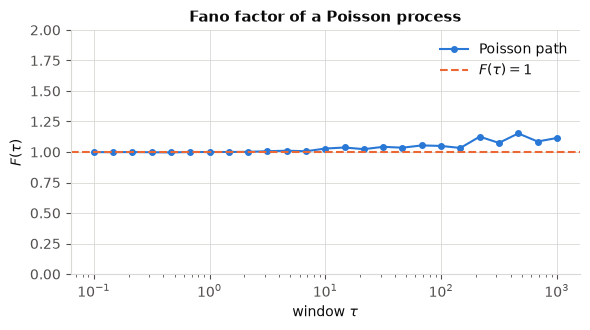

In [3]:

rng = np.random.default_rng(3)
t = poisson_process(2.0, 200000.0, rng)
taus = np.logspace(-1, 3, 25)
fano = []
for tau in taus:
    c = np.bincount((t // tau).astype(int), minlength=int(200000 / tau))[: int(200000 / tau)]
    fano.append(c.var() / c.mean())
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.semilogx(taus, fano, "o-", color=BLUE, ms=4, label="Poisson path")
ax.axhline(1, color=ORANGE, lw=1.5, ls="--", label="$F(\\tau) = 1$")
ax.set(title="Fano factor of a Poisson process", xlabel=r"window $\tau$", ylabel=r"$F(\tau)$", ylim=(0, 2)); ax.legend()
plt.tight_layout(); plt.show()